# Air raid alerts in Ukraine — training and validation

**Task.** For every oblast, every hour, predict

$$P(\text{the oblast is under air raid alert at some point in the next } h \text{ hours}), \qquad h \in \{1, 3, 6\}.$$

| | |
|---|---|
| forecast time | end of every hour *t* (T = t + 1 h); only information available at T is used |
| target | `y_h = 1` if any oblast- or raion-level alert is active in the oblast during hours t+1 … t+h |
| data | official alerts, **2025-11-01 → 2026-09-04 00:00 Kyiv** (raion-level alerting, before the yellow/red system) — see `eda.ipynb` |
| validation | 4 two-week folds spread over **Feb – Jun 2026**: hyperparameter tuning and seasonal robustness |
| test | the **last 5 weeks of reliable official data, 20 Jul – 24 Aug 2026**, in 4 rolling folds (see section 2 for why it ends on 24 Aug) |
| metrics | Brier score (main), log loss, ROC AUC — pooled and per oblast; separately for hours with and without an active alert |

The code lives in `ua_alerts/` (`features.py`, `models.py`, `tuning.py`, `backtest.py`, `evaluation.py`); this notebook runs and explains it.

In [1]:
import sys, json; sys.path.insert(0, "..")
%matplotlib inline
import pandas as pd
pd.set_option("display.width", 200); pd.set_option("display.max_columns", 30); pd.set_option("display.max_colwidth", 100)
from ua_alerts import backtest, config, data, evaluation, features, models

## 1. Data and features

The hourly alert state of each oblast is turned into a panel with one row per (hour, oblast).
All features are computed from hours ≤ t:

| group | features | motivation (EDA) |
|---|---|---|
| own state | `active_now` (alert at the forecast moment), `cov_0`, `cov_1` (share of the last two hours under alert), `hours_in_alert`, `hours_quiet` | persistence dominates short-term dynamics |
| own history | rolling share under alert over 3 h / 6 h / 24 h / 7 d, alert starts in the last 1 / 6 / 24 h, same hour yesterday / last 7 days | recent level matters more than long-term averages |
| regional state | national share under alert, number of oblasts with new alerts in the last 1 / 3 h, share under alert and new alerts per macro-region (west / center / south / front) | alerts propagate between rear oblasts (onset lift 10–23×) |
| calendar | Kyiv hour of the first target hour | daily cycle with up to 7× amplitude in the rear |
| identity | `region_id` (categorical) | base rates differ from 1 % to 96 % |

Day of week and month are deliberately left out — the EDA found no evidence for them.

In [2]:
panel, indicator = backtest.load_inputs()
window = panel.loc[pd.Timestamp(config.REGIME_START):]
print(f"panel: {len(panel):,} rows (hour x oblast); modelling window: {len(window):,} rows, "
      f"{window.index.get_level_values('time').nunique():,} forecast hours x {window.index.get_level_values('region').nunique()} oblasts")
pd.DataFrame({"mean": window[features.FEATURES[:-1]].mean(), "std": window[features.FEATURES[:-1]].std()}).round(3).T

panel: 940,728 rows (hour x oblast); modelling window: 176,808 rows, 7,367 forecast hours x 24 oblasts


,active_now,cov_0,cov_1,cov_mean_3h,cov_mean_6h,cov_mean_24h,cov_mean_168h,starts_1h,starts_6h,starts_24h,hours_in_alert,hours_quiet,cov_same_hour_1d,cov_same_hour_7d,national_active,national_starts_1h,national_starts_3h,west_active,center_active,south_active,front_active,west_starts_3h,center_starts_3h,south_starts_3h,front_starts_3h,hour
mean,0.277,0.277,0.277,0.277,0.277,0.277,0.277,0.490,2.940,11.743,11.904,35.655,0.277,0.277,0.277,4.177,8.219,0.021,0.145,0.240,0.792,0.412,2.140,1.577,4.090,11.501
std,0.448,0.415,0.415,0.386,0.368,0.342,0.324,1.372,4.414,13.718,45.764,77.632,0.415,0.340,0.138,3.075,3.931,0.113,0.228,0.326,0.239,1.498,2.075,1.145,1.327,6.922


### Leakage test

For random forecast times T, the features are rebuilt from a dataset **truncated at T** (alerts still running at T are cut at T,
nothing after T exists) and compared with the features built from the full data — they must be identical. The test was also
checked to *fail* when a one-hour look-ahead was injected on purpose (`cov_1 = cov.shift(-1)`), so it does detect leakage.

In [3]:
from tests.test_leakage import test_features_do_not_use_future_data
test_features_do_not_use_future_data()
print("leakage test passed: features at time T are identical with and without data after T")

leakage test passed: features at time T are identical with and without data after T


## 2. Validation design

* **Two sets of folds.** *Validation*: 4 two-week folds spread over Feb–Jun 2026 (winter, spring, early summer) — used to tune
  hyperparameters and to check that conclusions are not specific to one season. *Test*: the 35 days before **24 Aug 2026** in
  4 consecutive folds (~8.75 days each) — the latest period with reliable official data.
* **Rolling origin.** Every fold is forecast by models trained only on data before it; models are re-trained per fold and, within a
  fold, forecast every hour from the actually observed data up to that hour (like a model retrained every ~9 days in production).
* **Two training-window schemes.** *Expanding*: train on everything since 2025-11-01. *Sliding*: only the 12 weeks before the fold.
* **Purging.** A training row at hour t has the target window t+1 … t+h; rows whose target window reaches into the evaluated fold are dropped.
* **Metrics.** Brier score is the main metric (it rewards ranking and calibration). Log loss punishes confident mistakes.
  ROC AUC is reported **pooled** and as the **mean of per-oblast AUCs** — pooled AUC is inflated because any model that separates
  front-line oblasts (alert 95 % of the time) from the west (1–3 %) gets a high pooled AUC.
  *Brier skill* = 1 − Brier(model) / Brier(hour-of-day rate).

* **Why the test period ends on 24 Aug, not 4 Sep.** The city track (`city_track.ipynb`) showed that the official feed was already
  **missing alerts in its last ~2 weeks**: Kyiv alerts posted by the city administration and confirmed by the volunteer data are absent,
  and nationally official alert starts drop while volunteer starts rise (volunteer/official ratio 0.29–0.35 all summer, then 0.40 / 0.44 / 0.60).
  The first version of this notebook tested on 30 Jul – 3 Sep; its last fold looked "unusually easy" and inflated the scores
  (Brier skill 0.36 at 3 h vs 0.24 now). The cut-off was moved because of this **data-quality evidence**, found independently of the model
  scores; the earlier version remains in the git history.

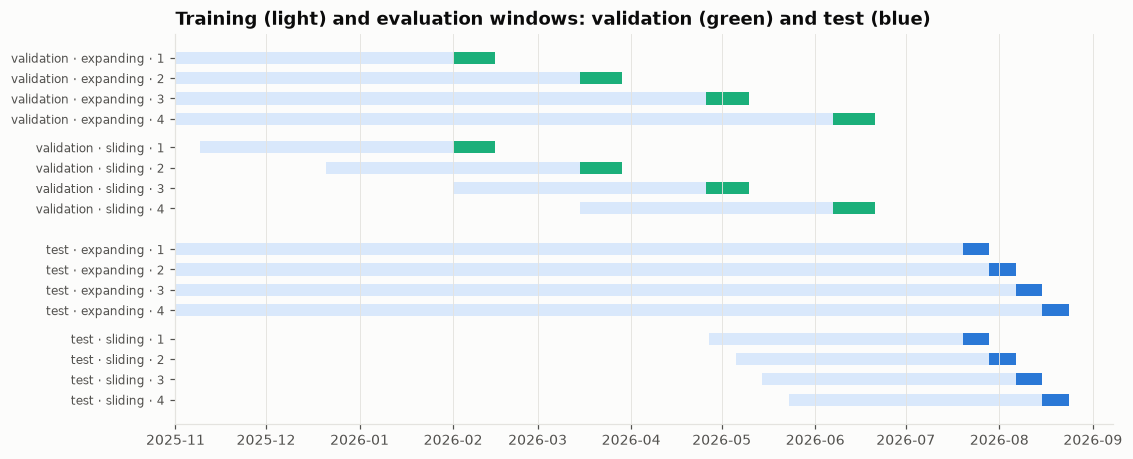

In [4]:
evaluation.plot_folds()

## 3. Models

| group | model | idea |
|---|---|---|
| baseline | **persistence** | an alert active now continues; no alert now stays quiet (naive walk without drift — drift is meaningless for a bounded 0/1 series) |
| baseline | **hour-of-day rate** | training frequency of `y_h` per oblast and Kyiv hour |
| ETS | **ETS(A,N,N), ETS(A,N,A), ETS(A,A,A), ETS(A,Ad,A)** | additive exponential smoothing of the hourly 0/1 alert indicator per oblast, seasonal period 24 h. Parameters by maximum likelihood on training data; the filter then runs forward with fixed parameters, so the state at t uses only data ≤ t. The max of the 1…h-step forecasts is mapped to a probability by a **per-oblast** logistic calibration |
| ETS | **AutoETS** | per oblast, the spec with the lowest AICc on the training window. Multiplicative error/seasonality is excluded: the series contains zeros |
| statistical | **logistic AR** | logistic regression on the features above — the binary-data analogue of an autoregressive model |
| ML | **LightGBM**, **XGBoost** | gradient-boosted trees on the same features |

ARIMA was considered and rejected: it models a continuous Gaussian quantity, can forecast outside [0, 1], forecasts the expected
share of an hour under alert rather than P(any alert within h hours), and cannot use other oblasts' state.

## 4. Hyperparameter tuning (validation folds only)

Grid search for the feature-based models; criterion: mean Brier score over the 4 validation folds at h = 3 h, expanding window.
The search is **time-based** — ordinary random k-fold cross-validation would leak, because neighbouring hours are strongly
correlated and would end up on both sides of the split. ETS needs no tuning (maximum likelihood), the baselines have no parameters.

| model | grid |
|---|---|
| logistic AR | C ∈ {0.01, 0.1, 1, 10} |
| LightGBM | num_leaves ∈ {15, 31, 63} × min_child_samples ∈ {50, 200} × (learning rate, trees) ∈ {(0.03, 400), (0.1, 150)} |
| XGBoost | max_depth ∈ {4, 6, 8} × min_child_weight ∈ {5, 20} × (learning rate, trees) ∈ {(0.03, 400), (0.1, 150)} |

In [5]:
tuning = pd.read_csv(config.ROOT / "reports" / "tuning_results.csv")
print("selected:", json.dumps(backtest.load_tuned_params()))
summary = tuning.groupby("model")["mean_brier"].agg(best="min", worst="max", configs="size")
summary["spread_%"] = (100 * (summary.worst / summary.best - 1)).round(1)
summary.round(5)

selected: {"LightGBM": {"num_leaves": 15, "min_child_samples": 50, "learning_rate": 0.03, "n_estimators": 400}, "XGBoost": {"max_depth": 4, "min_child_weight": 5, "learning_rate": 0.03, "n_estimators": 400}, "logistic AR": {"C": 1.0}}


,best,worst,configs,spread_%
model,,,,
LightGBM,0.08364,0.08548,12,2.2
XGBoost,0.08349,0.08610,12,3.1
logistic AR,0.08468,0.08535,4,0.8


In [6]:
tuning.sort_values(["model", "mean_brier"]).groupby("model").head(3).round(5)

,model,params,mean_brier,fold_1,fold_2,fold_3,fold_4
4,LightGBM,"{""num_leaves"": 15, ""min_child_samples"": 50, ""learning_rate"": 0.03, ""n_estimators"": 400}",0.08364,0.10041,0.07428,0.07991,0.07996
6,LightGBM,"{""num_leaves"": 15, ""min_child_samples"": 200, ""learning_rate"": 0.03, ""n_estimators"": 400}",0.08373,0.10083,0.07414,0.08015,0.07981
8,LightGBM,"{""num_leaves"": 31, ""min_child_samples"": 50, ""learning_rate"": 0.03, ""n_estimators"": 400}",0.08383,0.10056,0.07523,0.07971,0.07980
16,XGBoost,"{""max_depth"": 4, ""min_child_weight"": 5, ""learning_rate"": 0.03, ""n_estimators"": 400}",0.08349,0.10060,0.07348,0.08036,0.07953
18,XGBoost,"{""max_depth"": 4, ""min_child_weight"": 20, ""learning_rate"": 0.03, ""n_estimators"": 400}",0.08358,0.10096,0.07353,0.08056,0.07926
19,XGBoost,"{""max_depth"": 4, ""min_child_weight"": 20, ""learning_rate"": 0.1, ""n_estimators"": 150}",0.08372,0.10151,0.07389,0.08022,0.07925
2,logistic AR,"{""C"": 1.0}",0.08468,0.10458,0.07362,0.08147,0.07904
3,logistic AR,"{""C"": 10.0}",0.08470,0.10457,0.07368,0.08149,0.07905
1,logistic AR,"{""C"": 0.1}",0.08473,0.10466,0.07355,0.08154,0.07919


* **Hyperparameters barely matter here**: the best and worst configuration differ by 2–3 % for the boosters and < 1 % for the
  logistic AR. The search prefers shallower trees (15 leaves / depth 4) to the initial guesses (31 leaves / depth 6).
* The **season matters far more** than the configuration: the same model scores ≈ 0.100 in February and ≈ 0.074 in March.
* On the test set the tuned XGBoost scores 0.0747 vs 0.0743 with the initial settings — tuning did not improve test performance,
  consistent with the flat validation surface. The tuned settings are kept because they were chosen by the pre-defined procedure.

## 5. Training and validation run

Every model is trained and evaluated for every (fold set, window scheme, fold, horizon), with the tuned hyperparameters.
Predictions are cached in `data/processed/backtest_predictions.parquet`; `rerun=True` retrains everything.

In [7]:
preds = backtest.run_all(rerun=False)   # set rerun=True to retrain everything (~6 min); run ua_alerts.tuning first to re-tune
board = backtest.leaderboard(preds)
preds.groupby(["set", "window", "h"]).size().unstack()

h                         1      3      6
set        window                        
test       expanding  20160  20160  20160
           sliding    20160  20160  20160
validation expanding  32256  32256  32256
           sliding    32256  32256  32256

## 6. Test results

Leaderboard on the test folds for h = 3 h (both window schemes):

In [8]:
evaluation.leaderboard_table(board, h=3)

group     brier         brier_skill          log_loss           roc_auc         roc_auc_mean_per_oblast        
window                                      expanding sliding   expanding sliding expanding sliding expanding sliding               expanding sliding
model                                                                                                                                                
LightGBM                                 ML    0.0743  0.0739      0.2433  0.2109    0.2338  0.2345    0.9653  0.9644                  0.7856  0.7562
LightGBM + Air Force              ML + text    0.0745  0.0737      0.2412  0.2127    0.2341  0.2323    0.9651  0.9652                  0.7840  0.7739
XGBoost + Air Force               ML + text    0.0746  0.0732      0.2410  0.2186    0.2346  0.2312    0.9648  0.9655                  0.7700  0.7723
XGBoost                                  ML    0.0747  0.0736      0.2397  0.2138    0.2353  0.2333    0.9646  0.9648                  0.7675  0.7609
logistic AR + Air Force  statistical + text    0.0751  0.0747      0.2354  0.2020    0.2373  0.2376    0.9646  0.9642                  0.7625  0.7394
logistic AR                     statistical    0.0755  0.0752      0.2309  0.1973    0.2381  0.2383    0.9643  0.9639                  0.7622  0.7365
ETS(A,A,A)                              ETS    0.0819  0.0811      0.1658  0.1335    0.2665  0.2643    0.9587  0.9576                  0.6691  0.6081
ETS(A,Ad,A)                             ETS    0.0821  0.0812      0.1645  0.1327    0.2668  0.2645    0.9586  0.9575                  0.6688  0.6071
ETS(A,N,A)                              ETS    0.0821  0.0812      0.1645  0.1328    0.2668  0.2645    0.9586  0.9575                  0.6688  0.6071
AutoETS                                 ETS    0.0823  0.0808      0.1617  0.1371    0.2677  0.2634    0.9583  0.9578                  0.6455  0.5881
ETS(A,N,N)                              ETS    0.0823  0.0808      0.1617  0.1371    0.2679  0.2634    0.9583  0.9578                  0.6222  0.5881
hour-of-day rate                   baseline    0.0982  0.0937      0.0000  0.0000    0.3136  0.2995    0.9476  0.9466                  0.5272  0.5152
persistence                        baseline    0.1799  0.1799     -0.8312 -0.9207    1.6571  1.6571    0.8160  0.8160                  0.6794  0.6794

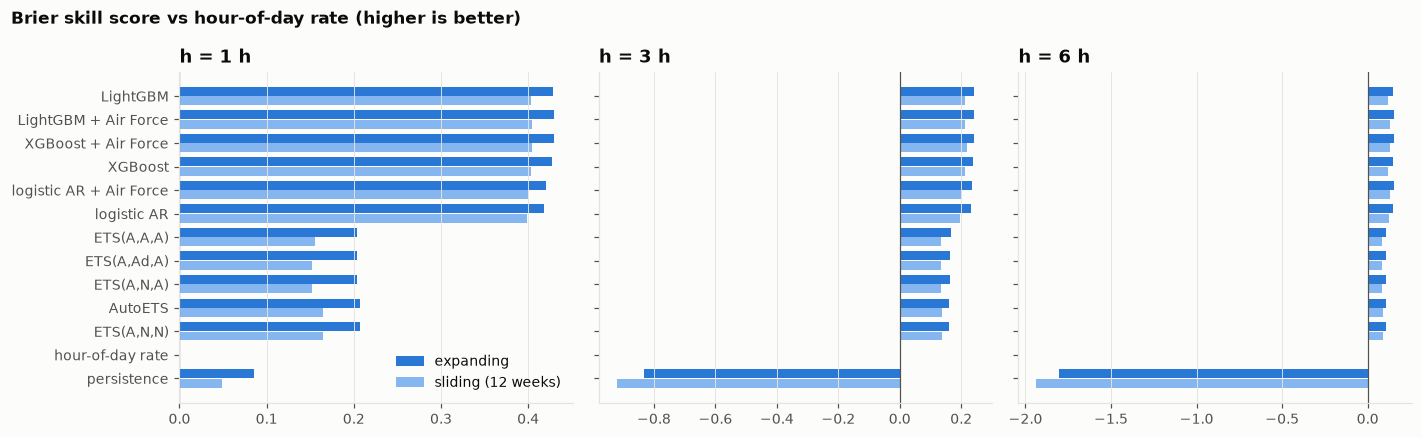

In [9]:
evaluation.plot_skill_by_horizon(board)

* **Ranking**: the three feature-based models (LightGBM, XGBoost, logistic AR) are practically tied, followed by the ETS family,
  the hour-of-day rate and persistence — at every horizon. At h = 3 h: LightGBM 0.0743, XGBoost 0.0747, logistic AR 0.0755,
  best ETS 0.0819, hour-of-day rate 0.0982. Brier skill vs the hour-of-day rate falls with the horizon: ≈ 0.43 at 1 h, 0.24 at 3 h, 0.15 at 6 h.
* **Window scheme — chosen on validation**: expanding is better on the validation folds at every horizon, so it is used. On the test weeks
  the sliding window is slightly better at 3–6 h (by ≈ 0.001) — the summer drifted away from the winter-spring training data; this is
  reported, not acted upon (choosing by test results would bias them).
* **Persistence** is good at 1 h but collapses at 3–6 h, and its hard 0/1 forecasts give a very poor log loss.
* **Correction made during this analysis.** The first ETS version used one logistic calibration pooled over all oblasts; the
  calibration plot showed it predicting ~12 % for quiet western oblasts (base rate 1 %). Per-oblast calibration fixed this.

**These headline numbers overstate the forecasting skill — see the next section.**

## 7. Where does the skill come from? Hours with vs without an active alert

If an alert is active at the forecast moment, "alert within h hours" is almost always true — the current alert continues into
the first target hour. Those rows (~30 %) are trivial: persistence alone gets them right. The real forecasting problem is the
**quiet hours: will a new alert start within h hours?**

In [10]:
main = ["persistence", "hour-of-day rate", "AutoETS", "logistic AR", "LightGBM", "XGBoost"]
onset = evaluation.onset_table(preds, panel, h=3)
print(onset[onset.model == "XGBoost"].set_index(["set", "state"])[["base_rate"]].round(3).T.to_string())
onset[onset.model.isin(main)].pivot_table(index="model", columns=["set", "state"],
                                          values=["brier_skill", "roc_auc_mean_per_oblast"]).loc[main].round(3)

set            test           validation          
state     alert now quiet now  alert now quiet now
base_rate     0.998      0.26      0.999     0.231


brier_skill                                roc_auc_mean_per_oblast                               
set                     test           validation                              test           validation          
state              alert now quiet now  alert now quiet now               alert now quiet now  alert now quiet now
model                                                                                                             
persistence            0.977    -1.352      0.985    -0.814                   0.500     0.500      0.500     0.500
hour-of-day rate       0.000     0.000      0.000     0.000                   0.601     0.512      0.735     0.493
AutoETS                0.711     0.004      0.723     0.008                   0.707     0.529      0.519     0.580
logistic AR            0.977     0.016      0.985     0.081                   0.538     0.602      0.452     0.709
LightGBM               0.977     0.032      0.985     0.092                   0.650     0.668      0.509     0.717
XGBoost                0.977     0.027      0.985     0.093                   0.557     0.639      0.553     0.718

In [11]:
quiet = pd.concat([evaluation.onset_table(preds, panel, h).assign(h=h) for h in config.HORIZONS])
quiet = quiet[quiet.state == "quiet now"]
quiet[quiet.model.isin(main)].pivot_table(index="model", columns=["set", "h"],
                                          values=["brier_skill", "roc_auc_mean_per_oblast"]).loc[main].round(3)

brier_skill                                        roc_auc_mean_per_oblast                                       
set                     test               validation                                  test               validation              
h                          1      3      6          1      3      6                       1      3      6          1      3      6
model                                                                                                                             
persistence           -0.513 -1.352 -2.236     -0.231 -0.814 -1.278                   0.500  0.500  0.500      0.500  0.500  0.500
hour-of-day rate       0.000  0.000  0.000      0.000  0.000  0.000                   0.512  0.512  0.515      0.494  0.493  0.489
AutoETS               -0.074  0.004  0.004     -0.025  0.008  0.012                   0.536  0.529  0.520      0.576  0.580  0.589
logistic AR            0.045  0.016  0.022      0.169  0.081  0.071                   0.580  0.602  0.566      0.681  0.709  0.717
LightGBM               0.061  0.032  0.018      0.182  0.092  0.069                   0.645  0.668  0.560      0.692  0.717  0.693
XGBoost                0.060  0.027  0.017      0.182  0.093  0.072                   0.625  0.639  0.553      0.687  0.718  0.695

* **With an alert active now, the target is 1 in 99.8 % of cases** — every model (and persistence) is near-perfect there, and
  these rows produce most of the headline skill.
* **On quiet hours — the honest measure — the skill is small.** At h = 3 h the best models reach a Brier skill of **0.03 on the test
  weeks and 0.09 on the validation folds**; their mean per-oblast ROC AUC is **0.64–0.67 (test) / 0.72 (validation)**, against ≈ 0.51 for the
  hour-of-day rate. So the models *rank* quiet hours clearly better than the clock, but their probabilities improve only a little on a
  good base rate. The boosters are the best models on quiet hours in both sets; AutoETS is no better than the baseline there.
* **Practical meaning**: the model is reliable at saying *"the current alert will still be on"* and *"it is quiet and likely to stay quiet"*;
  early warning of **new** alerts from the alert history alone is weak.

## 8. Validation vs test — does the ranking hold across seasons?

In [12]:
evaluation.season_table(board, h=3)

brier            brier_skill            roc_auc_mean_per_oblast           
set                        test validation        test validation                    test validation
model                                                                                               
LightGBM                 0.0743     0.0836      0.2433     0.2828                  0.7856     0.8325
LightGBM + Air Force     0.0745     0.0836      0.2412     0.2829                  0.7840     0.8311
XGBoost + Air Force      0.0746     0.0833      0.2410     0.2852                  0.7700     0.8321
XGBoost                  0.0747     0.0835      0.2397     0.2840                  0.7675     0.8338
logistic AR + Air Force  0.0751     0.0847      0.2354     0.2740                  0.7625     0.8317
logistic AR              0.0755     0.0847      0.2309     0.2739                  0.7622     0.8315
ETS(A,A,A)               0.0819     0.0985      0.1658     0.1557                  0.6691     0.7255
ETS(A,Ad,A)              0.0821     0.0985      0.1645     0.1552                  0.6688     0.7257
ETS(A,N,A)               0.0821     0.0985      0.1645     0.1552                  0.6688     0.7257
AutoETS                  0.0823     0.0978      0.1617     0.1610                  0.6455     0.7107
ETS(A,N,N)               0.0823     0.0979      0.1617     0.1605                  0.6222     0.7098
hour-of-day rate         0.0982     0.1166      0.0000     0.0000                  0.5272     0.5134
persistence              0.1799     0.1667     -0.8312    -0.4295                  0.6794     0.7247

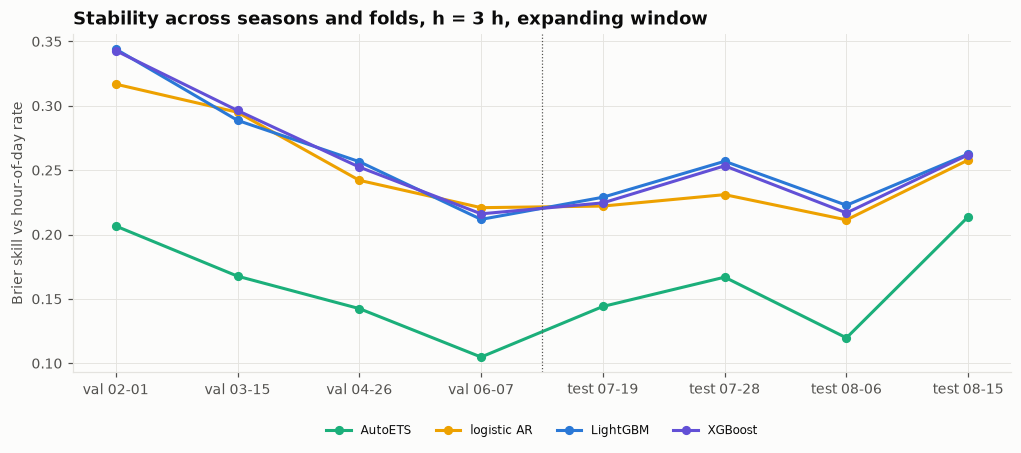

In [13]:
board_folds = backtest.summarize(preds, ["set", "window", "h", "fold"])
evaluation.plot_fold_stability(board_folds, h=3, window="expanding")

* **The ranking is stable**: in every fold of both sets the three feature-based models are close to each other and clearly above AutoETS.
* The **level** of skill varies between folds (≈ 0.21–0.34 vs the hour-of-day rate): it depends on how regular a period is, not on the model.
  The test folds (0.21–0.26) are slightly harder than the validation folds.

## 9. Exponential smoothing experiments

Which ETS spec does AICc choose per oblast (first test training window)? ΔAICc is relative to the best spec of the oblast.

In [14]:
fold_start = backtest.folds()[0][0]
sel = evaluation.ets_selection(indicator, pd.Timestamp(config.REGIME_START).tz_convert("UTC"), fold_start - pd.Timedelta(hours=1))
print(sel["chosen"].value_counts().to_string())
sel.astype({c: float for c in sel.columns if c != "chosen"}).round(3)

chosen
A,N,N    19
A,N,A     5


,"ΔAICc A,N,N","ΔAICc A,N,A","ΔAICc A,A,A","ΔAICc A,Ad,A",chosen,alpha,gamma (seasonal)
Cherkaska oblast,0.000,250.528,262.468,256.408,"A,N,N",0.411,NaN
Chernihivska oblast,0.000,289.038,295.338,295.148,"A,N,N",0.503,NaN
Chernivetska oblast,0.000,178.828,182.866,184.886,"A,N,N",0.503,NaN
Dnipropetrovska oblast,6.972,0.000,4.038,6.058,"A,N,A",0.135,0.026
Donetska oblast,42.480,0.000,12.668,5.957,"A,N,A",0.196,0.032
Ivano-Frankivska oblast,0.000,217.890,221.928,223.948,"A,N,N",0.423,NaN
Kharkivska oblast,64.305,0.000,68.115,4.456,"A,N,A",0.137,0.033
Khersonska oblast,0.000,165.123,169.540,171.183,"A,N,N",0.427,NaN
Khmelnytska oblast,0.000,193.367,197.405,199.425,"A,N,N",0.599,NaN
Kirovohradska oblast,0.000,198.622,212.813,204.546,"A,N,N",0.388,NaN


In [15]:
ets_models = ["ETS(A,N,N)", "ETS(A,N,A)", "ETS(A,A,A)", "ETS(A,Ad,A)", "AutoETS"]
b = board[board.model.isin(ets_models) & (board.window == "expanding")]
b.pivot_table(index="model", columns=["set", "h"], values="brier").loc[ets_models].round(4)

set            test                 validation                
h                 1       3       6          1       3       6
model                                                         
ETS(A,N,N)   0.0806  0.0823  0.0779     0.0806  0.0979  0.1088
ETS(A,N,A)   0.0810  0.0821  0.0779     0.0813  0.0985  0.1097
ETS(A,A,A)   0.0809  0.0819  0.0778     0.0812  0.0985  0.1096
ETS(A,Ad,A)  0.0810  0.0821  0.0779     0.0813  0.0985  0.1097
AutoETS      0.0805  0.0823  0.0779     0.0804  0.0978  0.1088

* **AICc chooses the seasonal ETS(A,N,A) only for the five front-line oblasts** (Donetsk, Kharkiv, Sumy, Dnipropetrovsk, Zaporizhzhia).
  For all other oblasts the 24 seasonal states are not worth their cost (ΔAICc ≈ 85–290 against seasonality).
* **A trend never helps**: the estimated trend smoothing is ≈ 0, and (A,A,A) / (A,Ad,A) are practically identical to (A,N,A).
  That is expected for a bounded 0/1 indicator.
* **Out of sample, seasonality brings no consistent gain**: on the test weeks the seasonal specs are marginally better at 3 h, (A,N,N) at 1 h,
  equal at 6 h; on the validation folds (A,N,N) / AutoETS are marginally better at every horizon. All differences are ≤ 0.001 — within noise,
  matching the EDA (the daily cycle explains only a few percent of the hourly variance).
* ETS uses only the oblast's own history — the main reason it trails the feature-based models, which also see other oblasts.

## 10. Feature-based models: logistic AR vs LightGBM vs XGBoost

In [16]:
ml = ["logistic AR", "LightGBM", "XGBoost"]
board[board.model.isin(ml) & (board.window == "expanding")].pivot_table(
    index="model", columns=["set", "h"], values=["brier", "roc_auc_mean_per_oblast"]).round(4)

brier                                            roc_auc_mean_per_oblast                                           
set            test                 validation                                    test                 validation                
h                 1       3       6          1       3       6                       1       3       6          1       3       6
model                                                                                                                            
LightGBM     0.0581  0.0743  0.0742     0.0533  0.0836  0.0994                  0.8584  0.7856  0.6551     0.8842  0.8325  0.7910
XGBoost      0.0582  0.0747  0.0743     0.0533  0.0835  0.0991                  0.8501  0.7675  0.6488     0.8808  0.8338  0.7936
logistic AR  0.0591  0.0755  0.0739     0.0541  0.0847  0.0992                  0.8271  0.7622  0.6692     0.8808  0.8315  0.8049

In [17]:
f = board_folds[board_folds.model.isin(ml) & (board_folds.window == "expanding")]
wins = f.loc[f.groupby(["set", "h", "fold"])["brier"].idxmin()]
print("best feature-based model per (set, horizon, fold):", wins.model.value_counts().to_dict())
test = preds[preds.set == "test"]
ens = test.assign(**{"mean of 3": test[ml].mean(axis=1)})
eb = backtest.leaderboard(ens)
eb[(eb.window == "expanding") & eb.model.isin(ml + ["mean of 3"])].pivot_table(
    index="model", columns="h", values=["brier", "log_loss", "roc_auc_mean_per_oblast"]).round(4)

best feature-based model per (set, horizon, fold): {'LightGBM': 12, 'XGBoost': 6, 'logistic AR': 6}


brier                 log_loss                 roc_auc_mean_per_oblast                
h                 1       3       6        1       3       6                       1       3       6
model                                                                                               
LightGBM     0.0581  0.0743  0.0742   0.1872  0.2338  0.2434                  0.8584  0.7856  0.6551
XGBoost      0.0582  0.0747  0.0743   0.1876  0.2353  0.2437                  0.8501  0.7675  0.6488
logistic AR  0.0591  0.0755  0.0739   0.1920  0.2381  0.2419                  0.8271  0.7622  0.6692
mean of 3    0.0582  0.0744  0.0737   0.1877  0.2342  0.2415                  0.8568  0.7835  0.6598

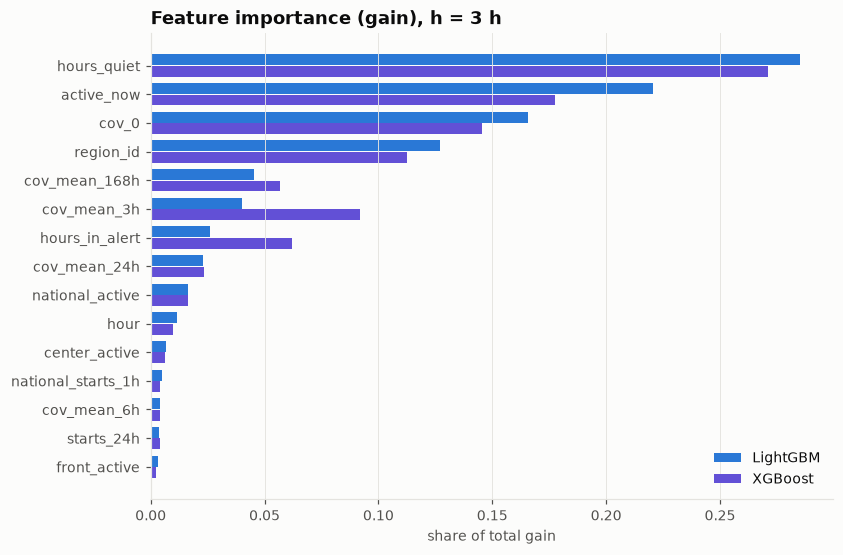

,hours_quiet,active_now,cov_0,region_id,cov_mean_168h,cov_mean_3h,hours_in_alert,cov_mean_24h,national_active,hour
LightGBM,0.285,0.220,0.165,0.127,0.045,0.040,0.026,0.023,0.016,0.012
XGBoost,0.271,0.178,0.146,0.113,0.057,0.092,0.062,0.024,0.016,0.010


In [18]:
imp = evaluation.feature_importance(panel, h=3)
evaluation.plot_feature_importance(imp, h=3)
imp.head(10).round(3).T

* **The three feature-based models are practically tied** (Brier differences ≤ 0.002). Across the 24 (set, horizon, fold) combinations
  LightGBM is best 12×, XGBoost 6×, logistic AR 6×.
* **Final model: XGBoost**, selected on the **validation** folds (0.0835 vs LightGBM 0.0836 at 3 h) — the rule fixed before the test.
  On the test weeks LightGBM is marginally ahead (0.0743 vs 0.0747): a tie either way.
* **Averaging the three** is best at 6 h on the test weeks and close elsewhere — no clear gain, not used.
* **Feature importance** is dominated by persistence (`hours_quiet`, `active_now`, `cov_0`) and oblast identity. Regional features have a
  small *total* gain — they matter for the rare new alerts in the rear, a small share of all rows.

## 11. Text data: Air Force Telegram messages (`@kpszsu`)

The alert history cannot see *why* alerts start. The Air Force publishes real-time reports — drone tracks per oblast
("Вінниччина: реактивний БпЛА у напрямку Козятина"), ballistic threats, missile launches and aircraft take-offs.
All public posts from 24 Oct 2025 to 5 Sep 2026 were scraped from the channel's web preview (`ua_alerts/telegram.py`);
a message is assigned to the hour in which it was **published**, so only messages published before the forecast time are used
(covered by the leakage test, which also fails when messages are shifted one hour early on purpose).

In [19]:
from ua_alerts import telegram, text_experiment
msgs = telegram.load("kpszsu")
print(f"{len(msgs):,} messages, {msgs.time.min():%Y-%m-%d} .. {msgs.time.max():%Y-%m-%d}")
print(msgs.set_index("time").resample("MS").size().rename("messages per month").to_string())
text_experiment.category_counts(msgs).T

30,950 messages, 2025-10-24 .. 2026-09-05
time
2025-10-01 00:00:00+00:00     643
2025-11-01 00:00:00+00:00    2576
2025-12-01 00:00:00+00:00    2550
2026-01-01 00:00:00+00:00    2881
2026-02-01 00:00:00+00:00    2632
2026-03-01 00:00:00+00:00    2399
2026-04-01 00:00:00+00:00    1805
2026-05-01 00:00:00+00:00    2421
2026-06-01 00:00:00+00:00    3504
2026-07-01 00:00:00+00:00    4025
2026-08-01 00:00:00+00:00    4704
2026-09-01 00:00:00+00:00     810
Freq: MS


,drones,ballistic,missiles,kab,MiG-31K take-off,strategic bombers
messages,20214,1454,298,4712,115,22


### Aircraft take-offs as early indicators

Idea: a take-off of missile carriers is reported before the missiles are launched, sometimes hours before.
Every strategic-aviation message, the national share of oblasts under alert at that moment and the maximum in the next 12 h:

In [20]:
text_experiment.aviation_events(msgs)

,posted (Kyiv),share under alert now,max share next 12 h,hours to max,message
0,2025-11-19 03:30,0.92,1.00,1.5,"✈ Відмічається активність 6-ти бортів Ту-95МС з аеродрому ""Оленья"" (Мурманська область., р"
1,2025-11-19 16:56,0.25,0.38,4.1,❗️Офіційно У багатоквартирні житлові будинки у місті Тернопіль влучили російські крилаті р
2,2025-12-06 05:13,0.92,1.00,1.8,🚀Ймовірно здійснено пуски крилатих ракет з літаків стратегічної авіації: Ту-95МС та Ту-160
3,2025-12-06 06:41,0.96,1.00,0.3,🚀Ймовірно здійснено пуски крилатих ракет з літаків стратегічної авіації: Ту-95МС та Ту-160
4,2025-12-12 10:33,0.33,0.38,4.4,"🚀Ракетна небезпека в областях, де оголошена тривога через загрозу пусків крилатих ракет з"
5,2026-01-05 17:00,0.25,0.25,-0.0,🛩На шляху до F-16: ексклюзивна історія від українського пілота ➖➖➖➖➖➖➖➖➖➖➖➖ Ексклюзивна ро
6,2026-01-20 03:50,0.38,0.75,2.2,✈ Виліт Ту-95МС з Оленьї! Можливі пуски крилатих ракет повітряного базування ближче до 6.0
7,2026-01-24 09:16,0.46,0.50,5.7,⚡️ ЗБИТО/ПОДАВЛЕНО 15 РАКЕТ ТА 357 ВОРОЖИХ БПЛА ➖➖➖➖➖➖➖➖➖➖ У ніч на 24 січня (з 18:00 23 с
8,2026-02-03 05:27,0.67,1.00,0.5,✈ Імовірно здійснено пуски крилатих ракет зі стратегічних бомбардувальників Ту-95МС з райо
9,2026-03-14 03:47,0.67,1.00,0.2,⚠Увага! 🚀Здійснено пуски крилатих ракет повітряного базування літаками Ту-95 та Ту-160 над


* **MiG-31K take-offs** (115 messages) are always posted as "Вся Україна — ракетна небезпека! Зафіксовано зліт МіГ-31К":
  the nationwide alert is declared *at* take-off, so they add no lead time over the alert data.
* **Strategic bombers** (Tu-95MS / Tu-160 / Tu-22M3): 22 keyword matches in ten months, and not all are take-offs — the pattern also
  catches launch reports, post-strike summaries and even an article about F-16 pilots. Genuine take-off warnings are a handful.
  Some do give hours of lead time: on 20 Jan 2026 at 03:50 "Виліт Ту-95МС з Оленьї! Можливі пуски … ближче до 6:00" — the Air Force
  even estimated the launch time, and the national share under alert rose from 0.38 to 0.75 within ~2 h. In other cases the wave
  was already running (19 Nov, 6 Dec: share 0.92) or none followed (Tu-22M3 over the Black Sea, August).
* **Verdict:** physically plausible, but far too rare in this channel to train or validate a feature. Not used.

In [21]:
text_experiment.mention_table(preds, panel)

hours  actual_new_alert_rate  xgboost_predicted
macro-region mentioned                                                 
center       False       4822                  0.331              0.305
             True         149                  0.664              0.449
front        False        458                  0.910              0.889
             True          94                  0.883              0.905
south        False       1416                  0.737              0.622
             True         290                  0.814              0.676
west         False       6673                  0.021              0.042
             True           9                  0.111              0.116

**Oblast mentions** (20 000+ drone messages): quiet oblast-hours in the test weeks, by whether the oblast was mentioned in the hour before
the forecast, compared with what the alert-only XGBoost predicted. In the centre a mention is followed by a new alert much more often than
the model expects (0.66 vs 0.45, 149 hours), in the south somewhat more often (0.81 vs 0.68); at the front no difference, in the west too few
hours (9) to tell. That suggested information beyond the alert history.

Text features added to the feature-based models (same tuned hyperparameters): per-oblast mentions in the last 1 / 3 h and national
message counts by type (drones, ballistic, missiles / aviation, guided bombs) in the last 1 / 3 h. Brier score with and without:

In [22]:
pairs = ["logistic AR", "LightGBM", "XGBoost"]
cmp = board[(board.window == "expanding") & board.model.str.replace(" + Air Force", "").isin(pairs)]
cmp.pivot_table(index="model", columns=["set", "h"], values="brier").round(4)

set                        test                 validation                
h                             1       3       6          1       3       6
model                                                                     
LightGBM                 0.0581  0.0743  0.0742     0.0533  0.0836  0.0994
LightGBM + Air Force     0.0580  0.0745  0.0738     0.0531  0.0836  0.0991
XGBoost                  0.0582  0.0747  0.0743     0.0533  0.0835  0.0991
XGBoost + Air Force      0.0580  0.0746  0.0737     0.0532  0.0833  0.0986
logistic AR              0.0591  0.0755  0.0739     0.0541  0.0847  0.0992
logistic AR + Air Force  0.0589  0.0751  0.0739     0.0541  0.0847  0.0994

In [23]:
pd.read_csv(text_experiment.RESULTS).round(5)

,set,variant,brier_all,brier_quiet,selected_on_validation
0,test,all text,0.07455,0.10735,True
1,test,no text,0.07468,0.10753,False
2,validation,all text,0.08335,0.11540,True
3,validation,mention counts,0.08344,0.11553,False
4,validation,mention yes/no,0.08339,0.11547,False
5,validation,no text,0.08349,0.11561,False


**Feature-set selection** (table above): the variant is selected on the validation folds by quiet-hour Brier, and only the selected variant
is compared with the alert-only model on the test folds.

* **The text features do not change the forecasts meaningfully.** On the validation folds every variant is within 0.0002 of the alert-only
  model; on the test weeks the selected variant is better by 0.0001 (all hours) / 0.0002 (quiet hours). Per model and horizon the differences
  are ≤ 0.0006 in either direction — noise. (With the first, longer test period, which included the two weeks of incomplete official data,
  the text features looked *worse*; that impression did not survive the corrected test period.)
* **Likely reasons.** (1) Largely redundant information: when drones are reported near an oblast, the oblasts on their route are usually
  already under alert, which the regional alert features capture. The strong residual signal in the centre concerns only 149 test hours.
  (2) The channel's activity doubled from ~2 500 to ~4 700 posts per month between winter and August, so counts learned in winter drift.
* **Decision:** the final model stays **alert-only XGBoost** — equal accuracy, and it does not depend on a second live data source.
  Making text useful would need a model of the *route* of drone groups (direction, speed, distance to each oblast) instead of mention counts.

## 12. Per-oblast results, forecasts over time, ROC and calibration

Oblasts are sorted by their test base rate (in brackets).

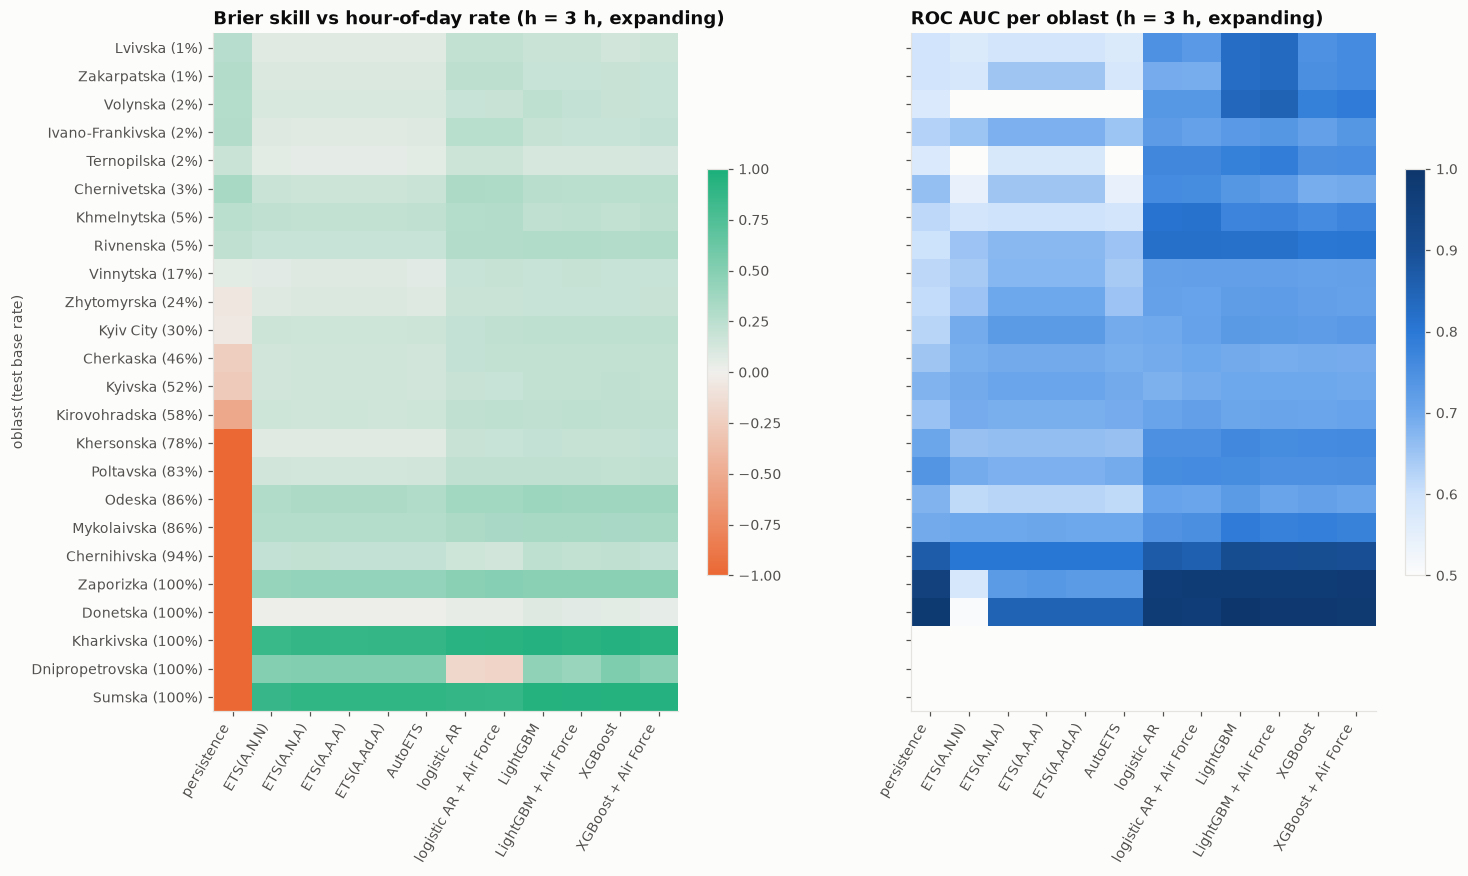

In [24]:
skill, auc = evaluation.plot_per_oblast(preds, h=3, window="expanding")

In [25]:
best = skill.drop(columns=["persistence"]).idxmax(axis=1)
pd.DataFrame({"best model (Brier)": best,
              "skill of best": skill.drop(columns=["persistence"]).max(axis=1).round(3),
              "LightGBM AUC": auc["LightGBM"].round(3), "XGBoost AUC": auc["XGBoost"].round(3)})

,best model (Brier),skill of best,LightGBM AUC,XGBoost AUC
region,,,,
Lvivska oblast,logistic AR,0.217,0.826,0.745
Zakarpatska oblast,logistic AR,0.240,0.825,0.751
Volynska oblast,LightGBM,0.227,0.839,0.783
Ivano-Frankivska oblast,logistic AR,0.265,0.730,0.714
Ternopilska oblast,logistic AR,0.170,0.783,0.749
Chernivetska oblast,logistic AR,0.313,0.732,0.689
Khmelnytska oblast,logistic AR + Air Force,0.282,0.772,0.759
Rivnenska oblast,XGBoost + Air Force,0.297,0.816,0.804
Vinnytska oblast,LightGBM + Air Force,0.197,0.716,0.712


### Forecasts over time

One test week for four oblasts representing the four regimes. Grey: hours with an alert. Lines: P(alert within 3 h) issued at each hour.

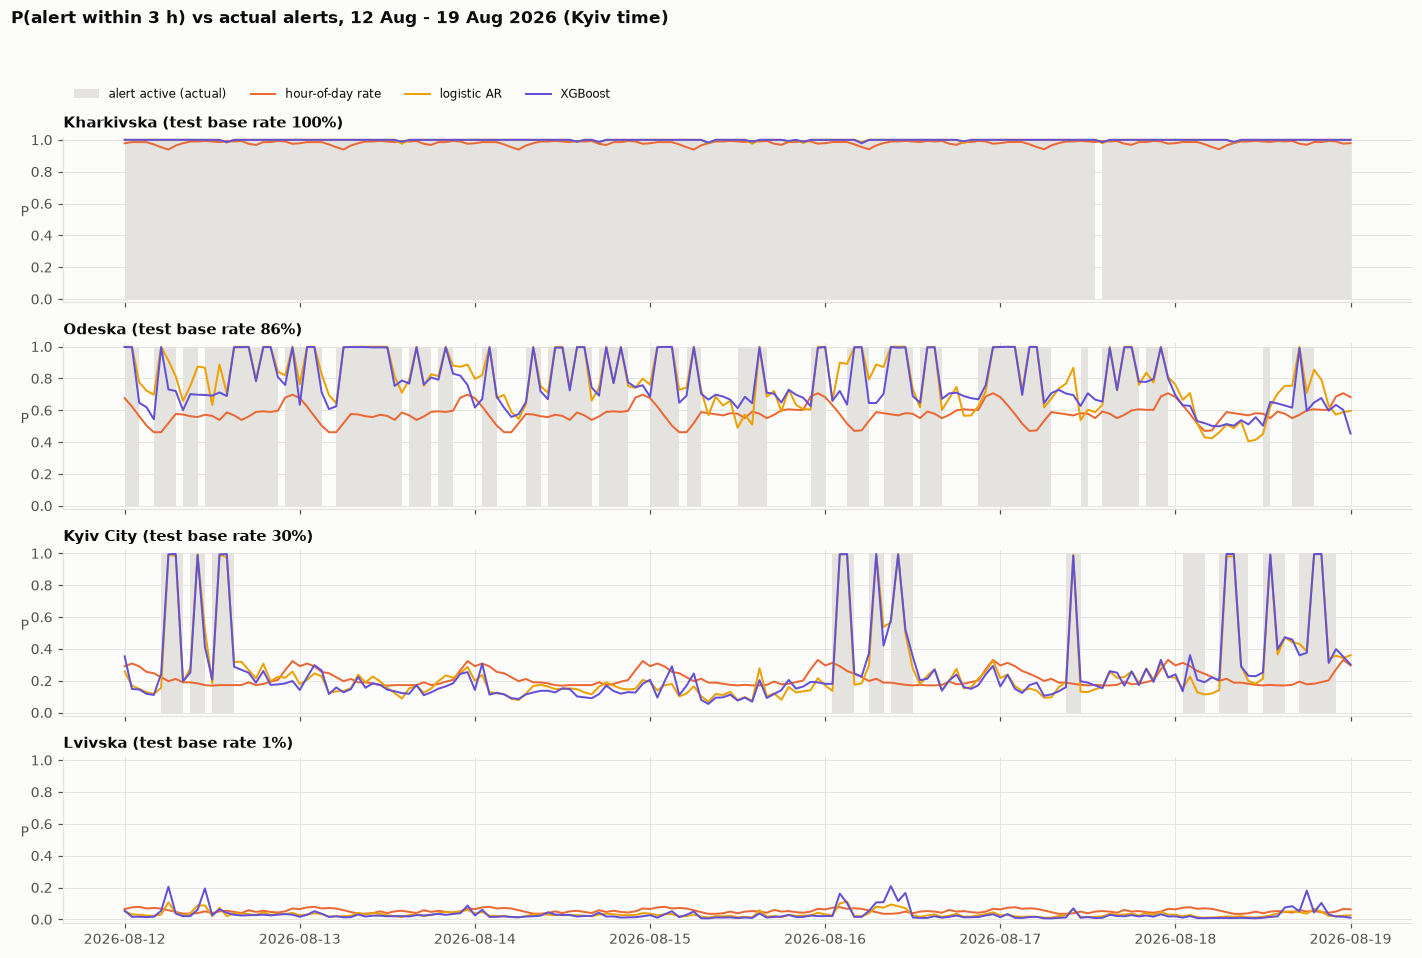

In [26]:
coverage = data.hourly_state(data.load_official(), end=data.regime_end())["coverage"]
evaluation.plot_predictions(preds, coverage, ["Kharkivska oblast", "Odeska oblast", "Kyiv City", "Lvivska oblast"],
                            start="2026-08-12", days=7, h=3)

* **Kharkiv (front)**: under alert practically all the time; every model predicts ≈ 1.
* **Odesa**: alerts are frequent and short; the forecasts jump to ≈ 1 during an alert and stay at 0.6–0.8 in the short quiet gaps — above the
  hour-of-day level, because a new alert usually follows soon.
* **Kyiv City**: between alerts the forecasts sit near the base level (≈ 0.1–0.3) and jump only once an alert has started (e.g. 16 Aug) —
  new alerts are not anticipated, as section 7 showed.
* **Lviv (west)**: the probability stays near 0, with small rises (≈ 0.2) when other oblasts are under alert; no alert followed in this week.

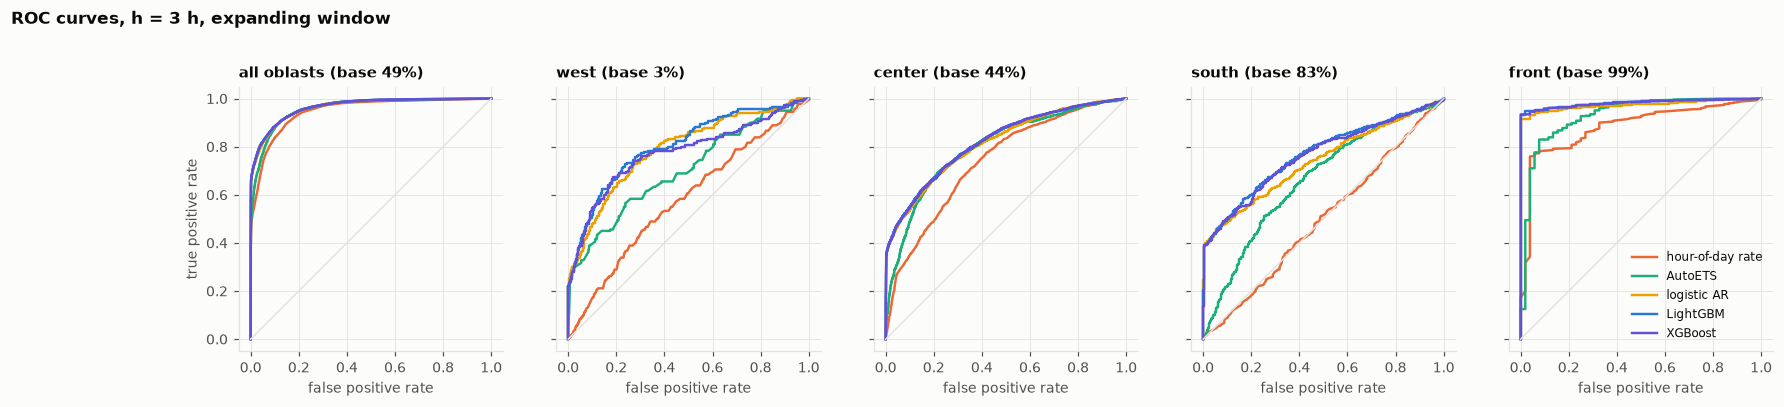

In [27]:
evaluation.plot_roc(preds, h=3, window='expanding')

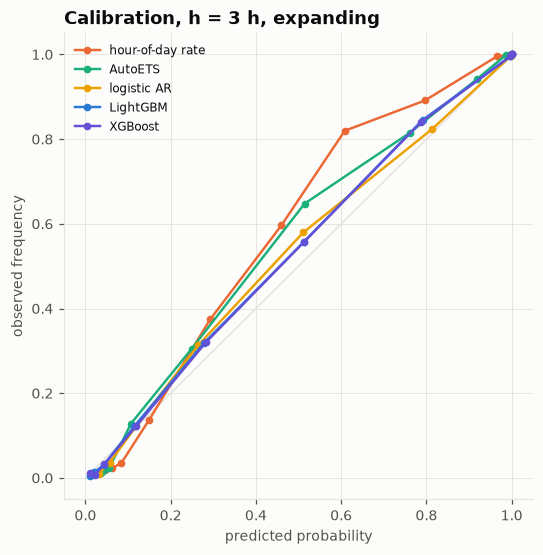

In [28]:
evaluation.plot_calibration(preds, h=3, window='expanding')

* **Middle oblasts (base rate 17–86 %)** — Kyiv, Cherkasy, Kirovohrad, Kherson, Poltava, Odesa, Mykolaiv: alerts are genuinely uncertain and
  the feature-based models add the most (Brier skill vs the hour-of-day rate 0.20–0.39).
* **West (base rate 1–6 %)**: the logistic AR (with or without text features) is the best model in 6 of 8 western oblasts. The test weeks
  were much quieter than training (2.7 % vs 7.3 % of hours followed by an alert within 3 h); Lviv and Zakarpattia had only 11 positive hours
  each, so model differences there are mostly noise.
* **Front line (base rate ≈ 100 %)**: Donetsk, Kharkiv, Sumy, Dnipropetrovsk and Zaporizhzhia were under alert practically all the time in the
  test weeks — nothing left to forecast.
* **Calibration**: the feature-based models lie close to the diagonal, with a slight under-prediction between 0.3 and 0.8; the hour-of-day
  rate under-predicts more strongly in that range.

## 13. Conclusions

* **Final model: XGBoost, expanding window, tuned and selected on the validation folds.** LightGBM and the logistic AR are equivalent
  within noise; the logistic AR is the best model in the quiet western oblasts.
* **Honest skill.** Over all hours, Brier skill vs the hour-of-day rate is 0.43 / 0.24 / 0.15 at 1 / 3 / 6 h on the test weeks — but almost
  all of it comes from predicting that a running alert continues. **For the real question — will a new alert start within 3 h? — the models
  rank hours clearly better than the clock (per-oblast ROC AUC 0.64–0.67 test / 0.72 validation vs ≈ 0.51), but the probability improvement is
  small (Brier skill 0.03 test / 0.09 validation).**
* **Robustness.** The ranking of model families is the same on the validation folds (Feb–Jun) and the test folds (Jul–Aug); hyperparameters matter little.
* **Data quality matters more than modelling here**: the official feed was incomplete in its last two weeks; testing on that period had
  inflated every score (3-h skill 0.36 instead of 0.24, quiet-hour skill 0.19 instead of 0.03).
* **Text data.** Air Force Telegram messages (drone tracks, launches, aircraft take-offs) were scraped and tested as features with the
  feature set chosen on validation folds only: no meaningful change (section 11). Aircraft take-offs are too rare to learn from; MiG-31K
  take-offs coincide with the alert itself.
* **Limitations.** The model predicts the *official alert*, not the threat itself; under the yellow/red system it would have to be re-trained
  (see the city track for a first look). Better early warning would need richer information — e.g. modelled drone routes.